In [138]:
options(warn = -1)
suppressMessages(require(Seurat))
suppressMessages(require(ggplot2))
suppressMessages(require(dplyr))
suppressMessages(require(reticulate))
suppressMessages(require(stringr))
suppressMessages(require(ggpubr))
suppressMessages(require(tidydr))
suppressMessages(require(CellTrek))
suppressMessages(require(CARD))
devtools::load_all('../Cell2Spatial/')

ℹ Loading Cell2Spatial


In [139]:
source('modules/globalParams.R')
source('modules/utils.R')
source('modules/vis.R')
source('modules/reformatProjRes.R')

In [140]:
out.figs.dir <- '../2.results/BRCA/figs'
out.data.dir <- '../2.results/BRCA/data'

In [141]:
dir.create(out.figs.dir, showWarnings = FALSE, recursive = TRUE)
dir.create(out.data.dir, showWarnings = FALSE, recursive = TRUE)

In [142]:
MTH_COLOR <- c(
    'Reference'    = 'grey',
    'Cell2Spatial' = '#F7B263',
    'CytoSPACE' = '#D6AA8E',
    'CellTrek' = '#99C0CC',
    'Tangram' = 'lightgreen',
    'Seurat' = '#CC00FF'
)

### Loading kidney ST and SC datasets 

In [143]:
brain.st <- readRDS('../0.data/BRCA/BRCA_SP1.RDS')

In [144]:
brain.sc <- readRDS('../0.data/BRCA/BRCA_SC.RDS')

In [145]:
brain.st <- brain.st %>% SCTransform(., verbose = FALSE, assay = 'Spatial') %>%
    RunPCA(verbose = FALSE) %>%
    RunUMAP(dims = 1 : 30, verbose = FALSE) %>%
    FindNeighbors(., dims = 1:30, verbose = FALSE) %>%
    FindClusters(., verbose = FALSE)

Found more than one class "dist" in cache; using the first, from namespace 'BiocGenerics'

Also defined by ‘spam’

Found more than one class "dist" in cache; using the first, from namespace 'BiocGenerics'

Also defined by ‘spam’



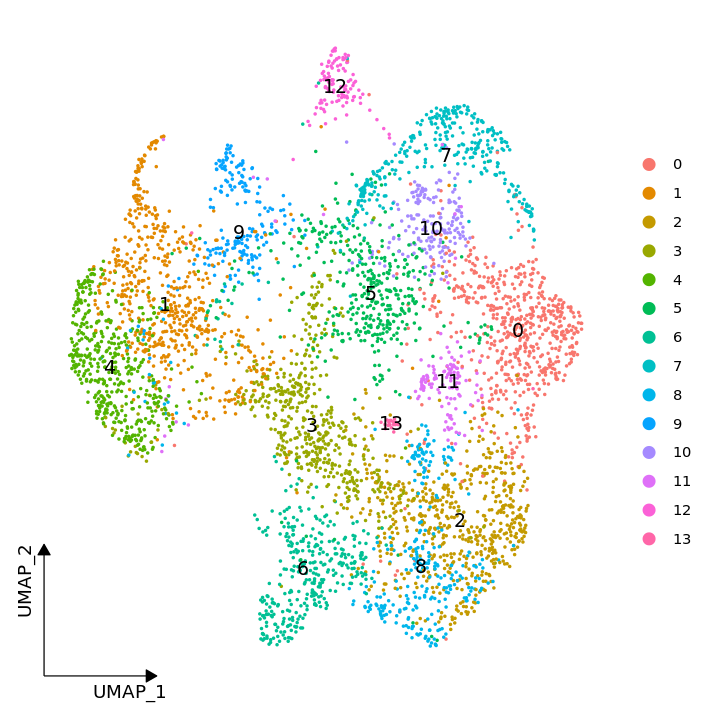

In [146]:
options(repr.plot.width = 6, repr.plot.height = 6)
DimPlot(brain.st, reduction = "umap", label = TRUE) + theme_dr(xlength = 0.2, ylength = 0.2, arrow = grid::arrow(length = unit(0.1, "inches"), ends = 'last', type = "closed")) + theme(panel.grid = element_blank())
ggsave(file.path(out.figs.dir, 'BRCA.ST.cluster.UMAP.dimplot.pdf'), width = 6, height = 6)

Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.


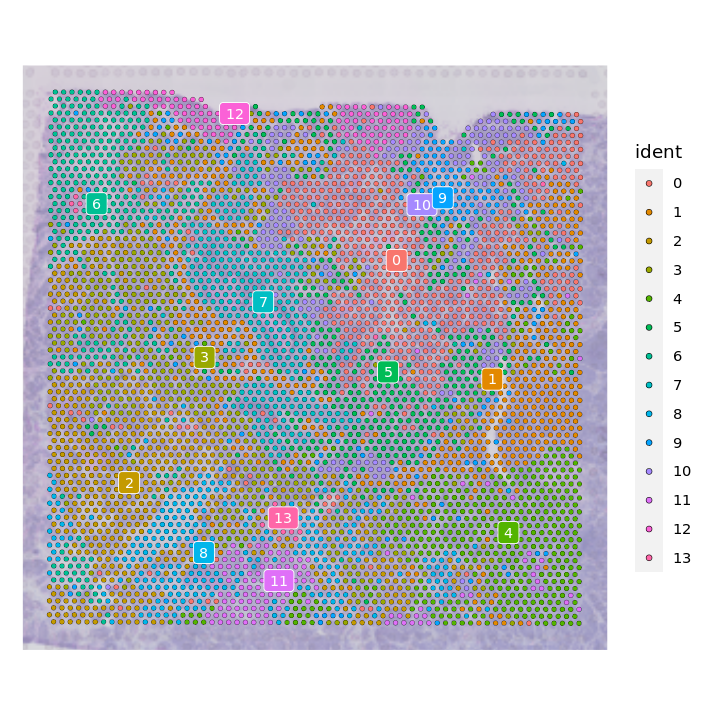

In [147]:
options(repr.plot.width = 6, repr.plot.height = 6)
SpatialDimPlot(brain.st, label = TRUE, label.size = 3, image.alpha = 0.5)
ggsave(file.path(out.figs.dir, 'BRCA.ST.cluster.UMAP.spatial.pdf'), width = 6, height = 6)

In [148]:
f.ctypes <- levels(brain.st)
gps <- lapply(f.ctypes, function(ct) {
    h.cells <- subset(brain.st, idents = ct) %>% Cells
    SpatialPlot(brain.st, cells.highlight = h.cells) + NoLegend() + ggtitle(ct) 
})

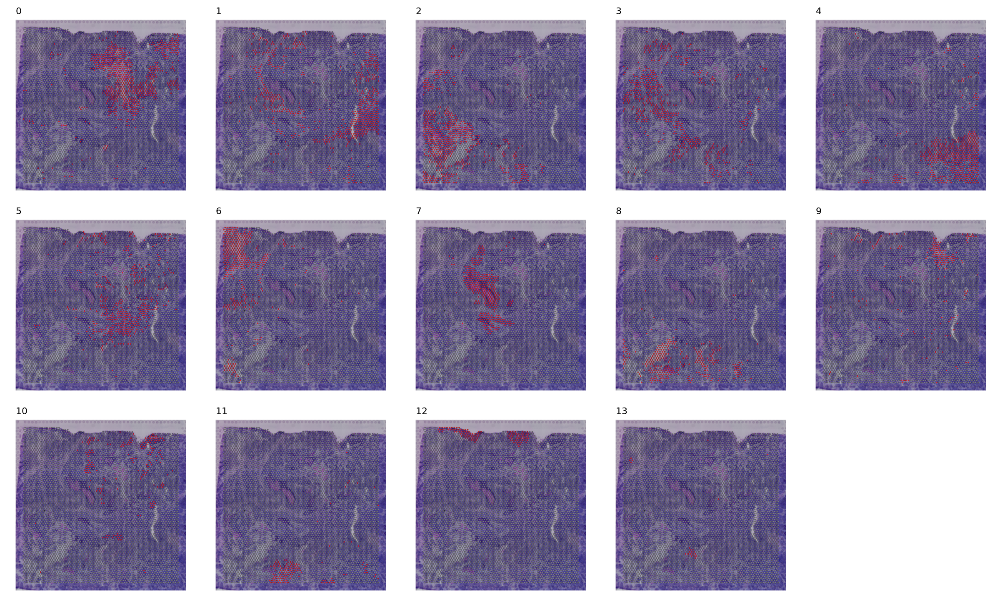

In [149]:
options(repr.plot.width = 20, repr.plot.height = 12)
ggarrange(plotlist = gps, nrow = 3, ncol = 5)

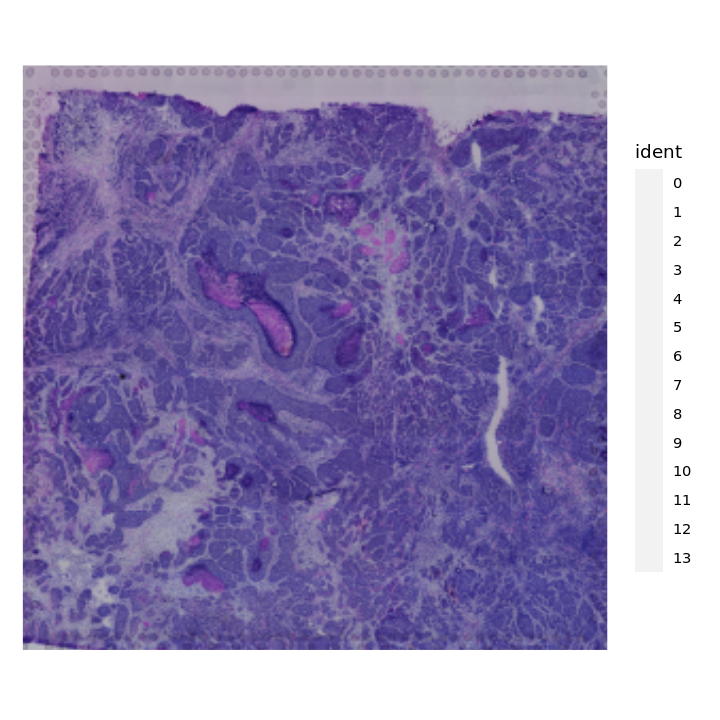

In [150]:
options(repr.plot.width = 6, repr.plot.height = 6)
SpatialDimPlot(brain.st, label = FALSE, label.size = 3,, alpha = 0)
ggsave(file.path(out.figs.dir, 'BRCA.ST.Image.spatial.pdf'), width = 6, height = 6)

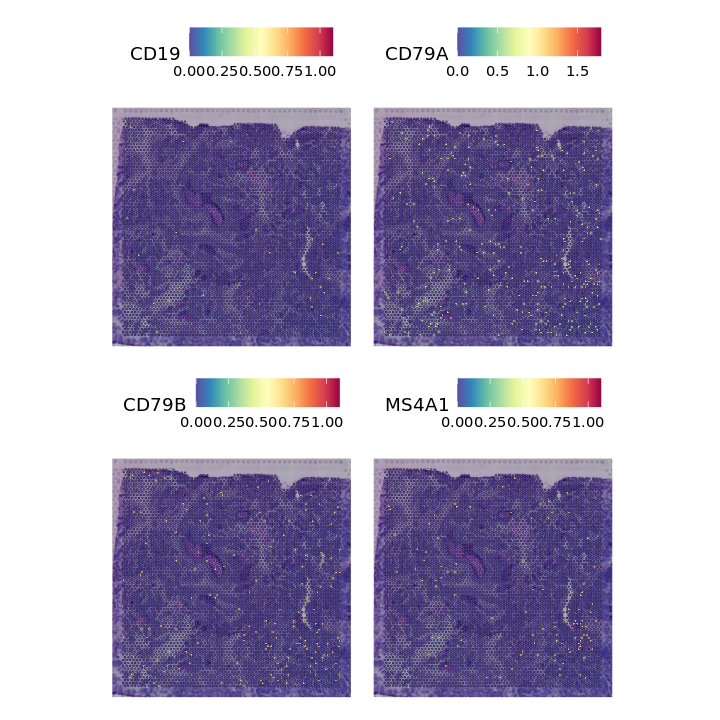

In [151]:
options(repr.plot.width = 6, repr.plot.height = 6)
SpatialFeaturePlot(brain.st, features = c('CD19', 'CD79A', 'CD79B', 'MS4A1'))

In [152]:
brain.sc@meta.data %>% head

,orig.ident,nCount_RNA,nFeature_RNA,X,percent.mito,subtype,celltype_subset,celltype_minor,celltype_major
,<chr>,<dbl>,<int>,<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>
CID4471_CCGGTAGAGATTACCC,CID4471,4143,1760,CID4471_CCGGTAGAGATTACCC,7.289404,ER+,Endothelial ACKR1,Endothelial ACKR1,Endothelial
CID3921_GGCAATTGTGATGTGG,CID3921,20181,4146,CID3921_GGCAATTGTGATGTGG,6.516030,HER2+,Endothelial ACKR1,Endothelial ACKR1,Endothelial
CID44041_GTCAAGTAGGGTGTTG,CID44041,1675,853,CID44041_GTCAAGTAGGGTGTTG,4.059701,TNBC,Endothelial ACKR1,Endothelial ACKR1,Endothelial
CID4530N_GCGCCAAGTCAGGACA,CID4530N,10408,3234,CID4530N_GCGCCAAGTCAGGACA,5.130669,ER+,Endothelial ACKR1,Endothelial ACKR1,Endothelial
CID4290A_GTCAAGTGTTAAGATG,CID4290A,2481,1240,CID4290A_GTCAAGTGTTAAGATG,9.633212,ER+,Endothelial ACKR1,Endothelial ACKR1,Endothelial
CID4471_CCCAGTTGTTGCGCAC,CID4471,6254,2100,CID4471_CCCAGTTGTTGCGCAC,5.052766,ER+,Endothelial RGS5,Endothelial RGS5,Endothelial


In [153]:
Idents(brain.sc) <- brain.sc$celltype_major

In [154]:
options(future.globals.maxSize = 5000000 * 1024^2, future.seed = TRUE)

brain.sc <- SCTransform(brain.sc, ncells = 3000, verbose = FALSE) %>%
    RunPCA(verbose = FALSE) %>%
    RunUMAP(dims = 1 : 30, verbose = FALSE)

Found more than one class "dist" in cache; using the first, from namespace 'BiocGenerics'

Also defined by ‘spam’

Found more than one class "dist" in cache; using the first, from namespace 'BiocGenerics'

Also defined by ‘spam’



In [155]:
set.seed(2023063) 
cell.colors <- randomcoloR::distinctColorPalette(length(unique(brain.sc$celltype_major))) %>% `names<-`(unique(brain.sc$celltype_major))

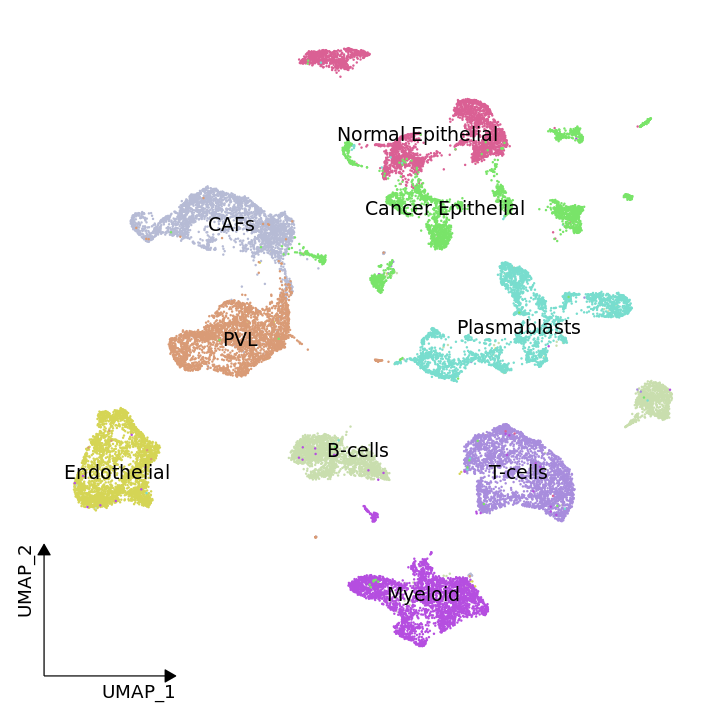

In [156]:
options(repr.plot.width = 6, repr.plot.height = 6)
DimPlot(brain.sc, label = TRUE, cols = cell.colors) + theme_dr(xlength = 0.2, ylength = 0.2, arrow = grid::arrow(length = unit(0.1, "inches"), ends = 'last', type = "closed")) + theme(panel.grid = element_blank()) + NoLegend()
ggsave(file.path(out.figs.dir, 'thymus.SC.cluster.UMAP.dimplot.pdf'), width = 6, height = 6)

In [157]:
levels(brain.sc) %>% length

[1] 9

In [315]:
dim(brain.sc)

[1] 23877 27000

In [316]:
dim(brain.st)

[1] 19451  4784

In [158]:
#markers <- FindAllMarkers(brain.st, only.pos = TRUE, logfc.threshold = 0.25, min.pct = 0.25, assay = 'SCT')

In [159]:
#openxlsx::write.xlsx(markers, file = file.path(out.data.dir, 'Thymus.ST.markers.xlsx'))

In [160]:
#top20.markers <- markers %>% group_by(cluster) %>% top_n(n = 50, wt = avg_log2FC)

In [161]:
#saveRDS(brain.sc, file = file.path(out.data.dir, 'brain.sc.RDS'))
#saveRDS(brain.st, file = file.path(out.data.dir, 'brain.st.RDS'))

In [308]:
cell.colors = c(
    'Endothelial' = '#C8D7A9', `B-cells` = '#9E8ABF', 
     CAFs = '#B4B7CF', PVL = '#8A559F', `T-cells` = '#C35685', 
    `Cancer Epithelial` = '#7CC9BF', `Normal Epithelial` = '#80C268',
    Myeloid = '#D18F6E', Plasmablasts = '#CECC57'
)

### Showing the projection performance for Cell2Spatial

In [309]:
cell2spatial <- readRDS('../2.results/BRCA/data/BRCA.1.cell2spatial.RDS')$obj

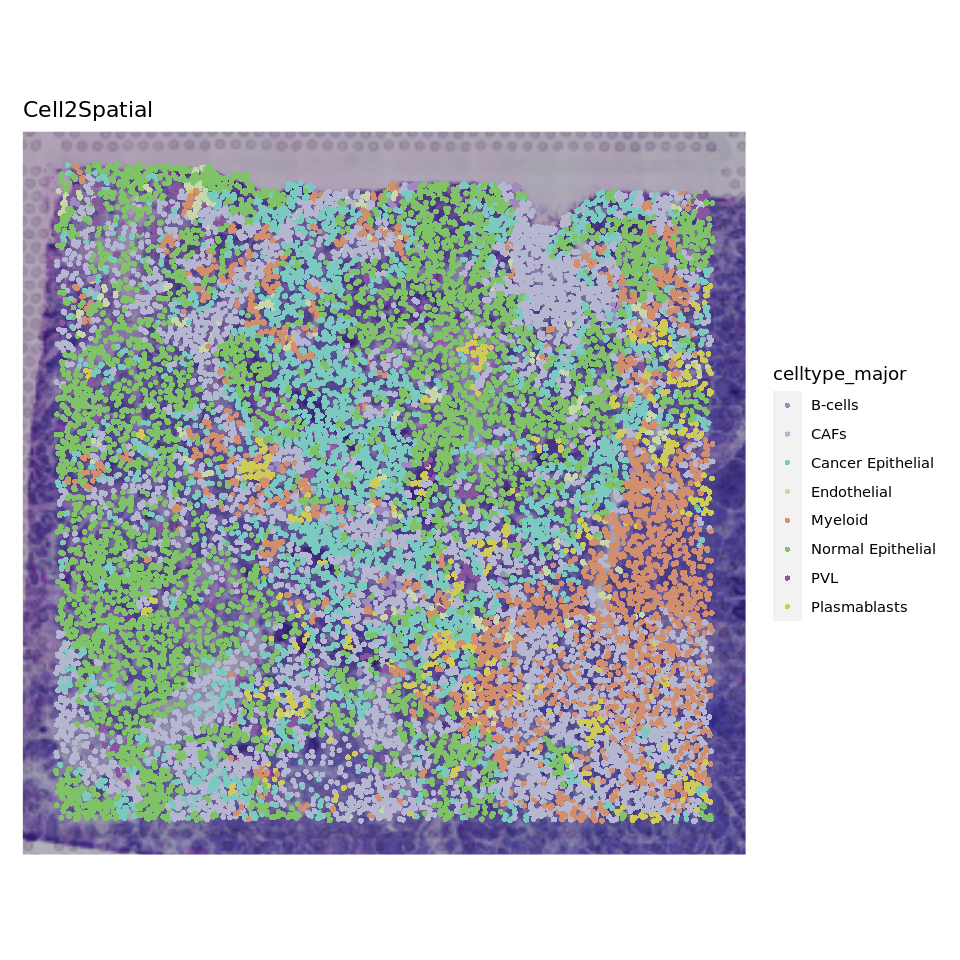

In [311]:
options(repr.plot.width = 8, repr.plot.height = 8)
SpatialPlot(cell2spatial, group.by = 'celltype_major', pt.size = 1.6, image.alpha = 1, stroke = 0, cols = cell.colors) + ggtitle('Cell2Spatial')
ggsave(file.path(out.figs.dir, 'cell2spatial.entire.UMAP.pdf'), width = 8, height = 6)

In [77]:
length(cell2spatial$celltype_major %>% unique)

[1] 9

In [78]:
f.ctypes <- cell2spatial$celltype_major %>% unique
gps <- lapply(f.ctypes, function(ct) {
    h.cells <- subset(cell2spatial, celltype_major == ct) %>% Cells
    obj.sub <- cell2spatial[, h.cells]
    SpatialDimPlot(obj.sub, image.alpha = 1, group.by = 'celltype_major',  pt.size.factor = 1.6, crop = FALSE, stroke = 0, cols = cell.colors[ct]) + ggtitle(ct) + NoLegend()  
})

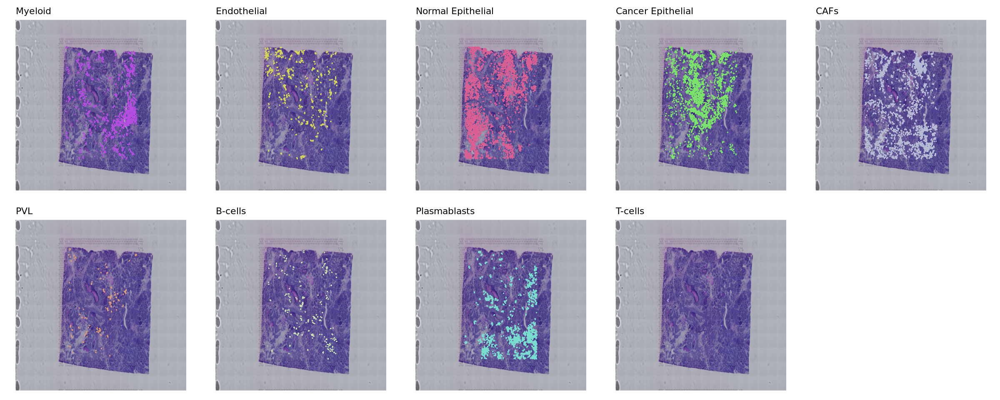

In [79]:
options(repr.plot.width = 20, repr.plot.height = 8)
ggarrange(plotlist = gps, nrow = 2, ncol = 5)
ggsave(file.path(out.figs.dir, 'cell2spatial.split.UMAP.pdf'), width = 20, height = 8)
ggsave(file.path(out.figs.dir, 'cell2spatial.split.UMAP.eps'), width = 20, height = 8)

### Showing the projection performance for CytoSpace

In [163]:
cytospace <- forCytoSpace('../2.results/BRCA/data/cytospace.1/', brain.sc, brain.st)

In [22]:
head(cytospace@meta.data)

,orig.ident,nCount_Spatial,nFeature_Spatial,UniqueCID,OriginalCID,CellType,SpotID,row,col,x.new,y.new
,<fct>,<dbl>,<int>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
UCID00000,Cell2Spatial,2833,682,UCID00000,CID3946_ATCCACCCAGGTCCCA,Endothelial,GGATCCCTACCAGCTA-1,89.05033,199.4468,90.56713,200.3190
UCID00001,Cell2Spatial,3579,886,UCID00001,CID4066_TATCAGGCAGACGCAA,Endothelial,AGTTGACGGTCCTTGC-1,283.93632,298.8743,282.48920,298.1176
UCID00002,Cell2Spatial,3456,947,UCID00002,CID4465_ATTACTCAGTTACGGG,Endothelial,AAATGACTGATCAAAC-1,321.46158,292.8702,322.85732,293.5635
UCID00003,Cell2Spatial,4327,1823,UCID00003,CID4471_GTCTTCGGTAGAGGAA,Endothelial,GTTAAGTTAGAGTGGG-1,185.27375,403.1512,183.69640,402.1294
UCID00004,Cell2Spatial,3523,1055,UCID00004,CID4530N_AAGCCGCAGAACTGTA,Endothelial,AACGTCATCCGGCTTG-1,324.85328,286.9672,323.69667,287.5179
UCID00005,Cell2Spatial,4640,2074,UCID00005,CID4471_GTCCTCAGTGCAGACA,Endothelial,TGGTCTGTTGGGCGTA-1,188.14588,232.4690,186.25692,231.9490


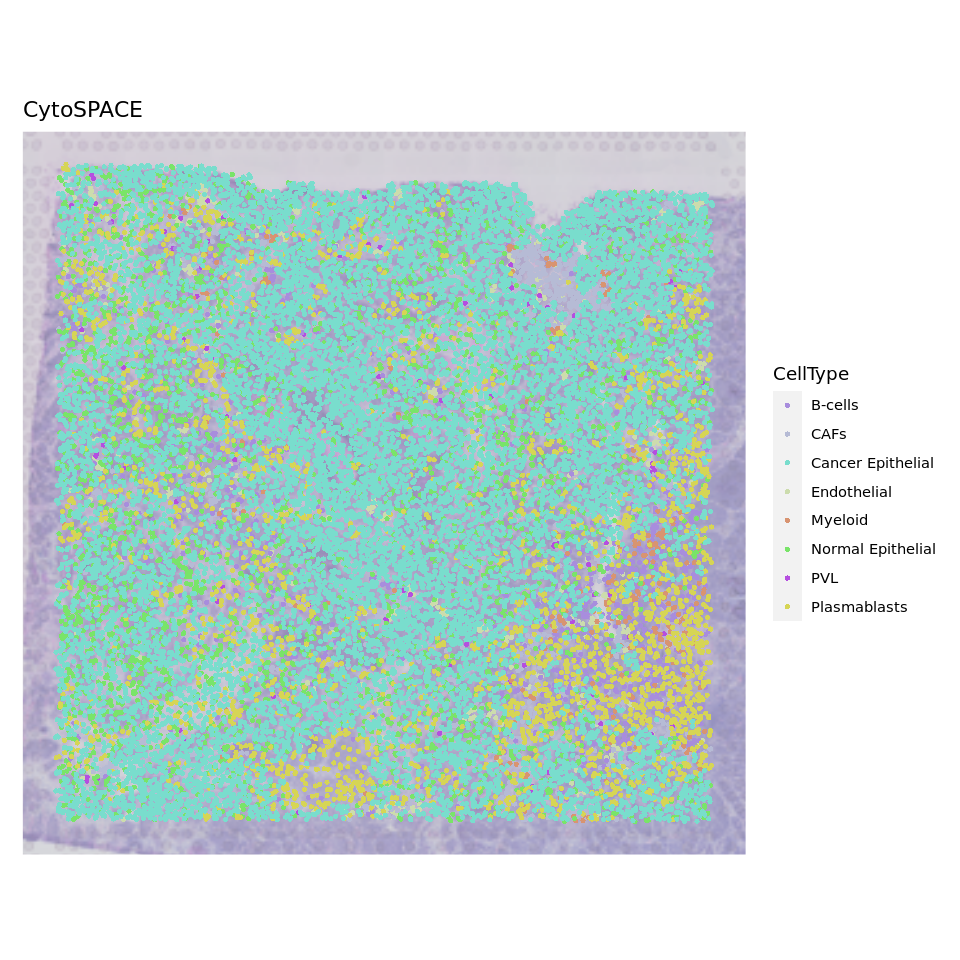

In [28]:
options(repr.plot.width = 8, repr.plot.height = 8)
SpatialPlot(cytospace, group.by = 'CellType', pt.size = 1.4, image.alpha = 0.5, cols = cell.colors, stroke = 0) + ggtitle('CytoSPACE')
ggsave(file.path(out.figs.dir, 'cytospace.entire.UMAP.pdf'), width = 8, height = 6)

In [29]:
length(cytospace$CellType %>% unique)

[1] 8

In [32]:
f.ctypes <- cytospace$CellType %>% unique
gps <- lapply(f.ctypes, function(ct) {
    h.cells <- subset(cytospace, CellType == ct) %>% Cells
    obj.sub <- cytospace[, h.cells]
    SpatialDimPlot(obj.sub, image.alpha = 1, group.by = 'CellType', cols = cell.colors[ct], pt.size.factor = 1.2, crop = FALSE, stroke = 0) + ggtitle(ct) + NoLegend()  
})

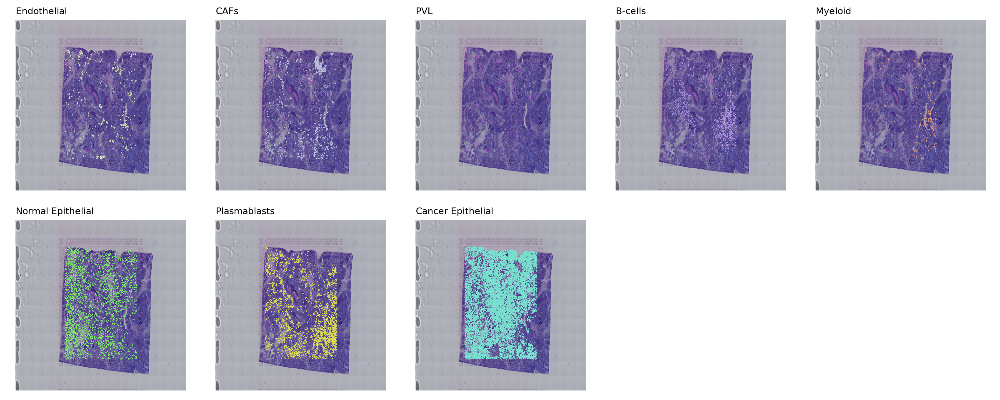

In [33]:
options(repr.plot.width = 20, repr.plot.height = 8)
ggarrange(plotlist = gps, nrow = 2, ncol = 5)
ggsave(file.path(out.figs.dir, 'cytospace.split.UMAP.pdf'), width = 20, height = 8)
ggsave(file.path(out.figs.dir, 'cytospace.split.UMAP.eps'), width = 20, height = 8)

### Showing the projection performance for tangram

In [164]:
tangram <- forTangram('../2.results/BRCA/data/BRCA.1_tangram.xls', brain.sc, brain.st)

In [35]:
tangram@meta.data %>% head

,orig.ident,nCount_Spatial,nFeature_Spatial,X.1,nCount_RNA,nFeature_RNA,X,percent.mito,subtype,celltype_subset,celltype_minor,celltype_major,SpotID,row,col,x.new,y.new
,<chr>,<dbl>,<int>,<chr>,<dbl>,<int>,<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
CID4471_CCGGTAGAGATTACCC,CID4471,4140,1760,CID4471_CCGGTAGAGATTACCC,4143,1760,CID4471_CCGGTAGAGATTACCC,7.289404,ER+,Endothelial ACKR1,Endothelial ACKR1,Endothelial,TATCCCTCGATCTGCA-1,321.62034,339.9500,322.61619,340.5227
CID3921_GGCAATTGTGATGTGG,CID3921,4365,1654,CID3921_GGCAATTGTGATGTGG,20181,4146,CID3921_GGCAATTGTGATGTGG,6.516030,HER2+,Endothelial ACKR1,Endothelial ACKR1,Endothelial,TGAGATTAGGCCCTAA-1,116.87675,360.2136,115.46271,359.4742
CID44041_GTCAAGTAGGGTGTTG,CID44041,3553,864,CID44041_GTCAAGTAGGGTGTTG,1675,853,CID44041_GTCAAGTAGGGTGTTG,4.059701,TNBC,Endothelial ACKR1,Endothelial ACKR1,Endothelial,CGTCTCTCGCCGAGGC-1,79.53912,425.0746,79.97665,425.2919
CID4530N_GCGCCAAGTCAGGACA,CID4530N,4816,2343,CID4530N_GCGCCAAGTCAGGACA,10408,3234,CID4530N_GCGCCAAGTCAGGACA,5.130669,ER+,Endothelial ACKR1,Endothelial ACKR1,Endothelial,GGATCCCTACCAGCTA-1,89.05033,199.4468,87.47297,198.4249
CID4290A_GTCAAGTGTTAAGATG,CID4290A,3526,1241,CID4290A_GTCAAGTGTTAAGATG,2481,1240,CID4290A_GTCAAGTGTTAAGATG,9.633212,ER+,Endothelial ACKR1,Endothelial ACKR1,Endothelial,GGAGGATTGAAAGGAG-1,86.01944,319.1090,85.22609,319.4867
CID4471_CCCAGTTGTTGCGCAC,CID4471,4700,2100,CID4471_CCCAGTTGTTGCGCAC,6254,2100,CID4471_CCCAGTTGTTGCGCAC,5.052766,ER+,Endothelial RGS5,Endothelial RGS5,Endothelial,CGCTGAGGACGTCCAA-1,75.58453,254.4068,74.60398,254.1369


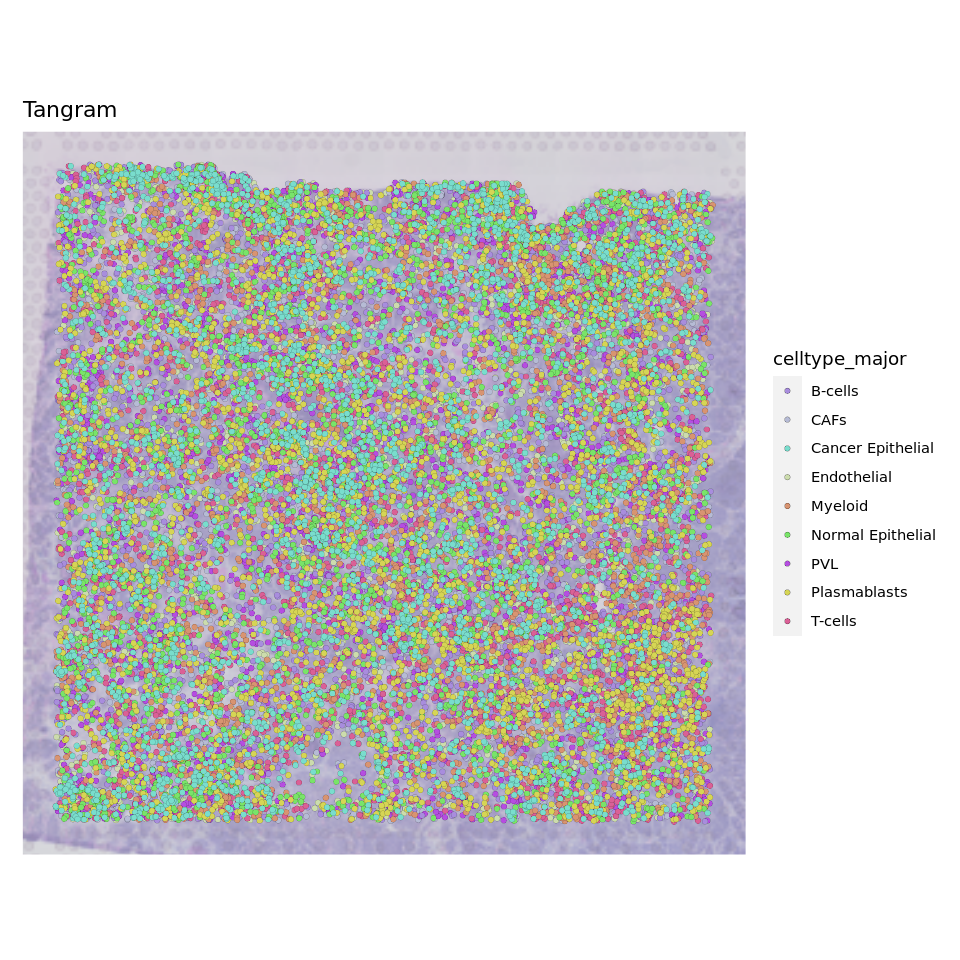

In [37]:
options(repr.plot.width = 8, repr.plot.height = 8)
SpatialPlot(tangram, group.by = 'celltype_major', pt.size = 1.6, image.alpha = 0.5, cols = cell.colors, stroke = 0.1) + ggtitle('Tangram')
ggsave(file.path(out.figs.dir, 'tangram.entire.UMAP.pdf'), width = 8, height = 6)

In [38]:
length(f.ctypes <- tangram$celltype_major %>% unique)

[1] 9

In [41]:
f.ctypes <- tangram$celltype_major %>% unique
gps <- lapply(f.ctypes, function(ct) {
    h.cells <- subset(tangram, celltype_major == ct) %>% Cells
    obj.sub <- tangram[, h.cells]
    SpatialDimPlot(obj.sub, image.alpha = 0.5, group.by = 'celltype_major', cols = cell.colors[ct], pt.size.factor = 1, crop = FALSE, stroke = 0) + ggtitle(ct) + NoLegend()  
})

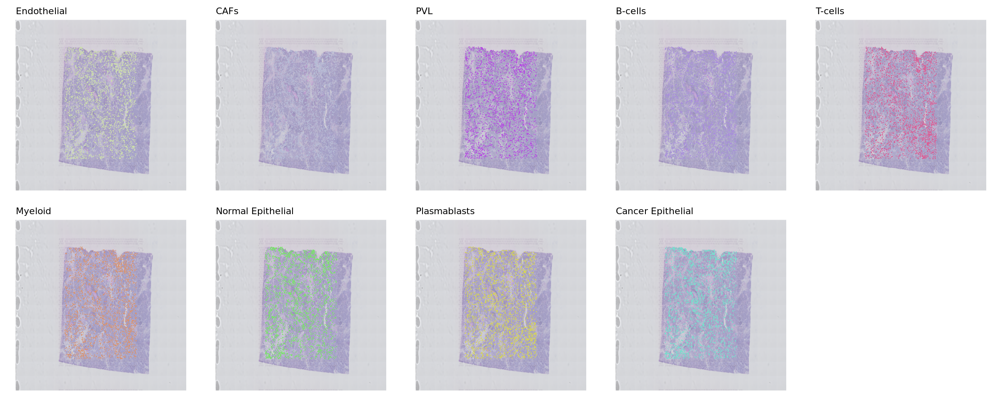

In [42]:
options(repr.plot.width = 20, repr.plot.height = 8)
ggarrange(plotlist = gps, nrow = 2, ncol = 5)
ggsave(file.path(out.figs.dir, 'tangram.split.UMAP.pdf'), width = 20, height = 8)
ggsave(file.path(out.figs.dir, 'tangram.split.UMAP.eps'), width = 20, height = 8)

### Showing the projection performance for Celltrek

In [27]:
cell.trek <- readRDS('../2.results/BRCA/data/BRCA.1.celltrek.RDS') %>% { forCellTrek(list(xx = .), brain.sc, brain.st) }

In [165]:
cell.trek <- readRDS(file.path(out.data.dir, 'celltrek.reformat.RDS'))

In [45]:
saveRDS(cell.trek, file = file.path(out.data.dir, 'celltrek.reformat.RDS'))
cell.trek@meta.data %>% head

,orig.ident,nCount_Spatial,nFeature_Spatial,nCount_RNA,nFeature_RNA,X,percent.mito,subtype,celltype_subset,celltype_minor,celltype_major,id_raw,id_new,coord_x,coord_y,Spot,centerX,centerY,imagerow,imagecol
,<chr>,<dbl>,<int>,<dbl>,<int>,<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
CID3946_AAACCCACAAATTAGG,CID3946,3014,692,932,554,CID3946_AAACCCACAAATTAGG,1.287554,TNBC,PVL Differentiated s3,PVL Differentiated,PVL,CID3946_AAACCCACAAATTAGG,CID3946_AAACCCACAAATTAGG,4465.851,12839.33,TGTTGGCTGGCGGAAG-1,65.12076,185.7789,64.45470,185.3073
CID3948_CGCTTCAAGTGCCATT,CID3948,3165,666,1136,591,CID3948_CGCTTCAAGTGCCATT,3.873239,ER+,PVL Differentiated s3,PVL Differentiated,PVL,CID3948_CGCTTCAAGTGCCATT,CID3948_CGCTTCAAGTGCCATT,4544.401,12906.18,TGTTGGCTGGCGGAAG-1,65.12076,185.7789,65.58840,186.2722
CID4290A_CAGTCCTGTCAGATAA,CID4290A,3450,705,1449,671,CID4290A_CAGTCCTGTCAGATAA,9.937888,ER+,PVL Differentiated s3,PVL Differentiated,PVL,CID4290A_CAGTCCTGTCAGATAA,CID4290A_CAGTCCTGTCAGATAA,4505.731,12836.22,TGTTGGCTGGCGGAAG-1,65.12076,185.7789,65.03027,185.2626
CID3946_AAGGAATGTGAGATCG,CID3946,3088,607,829,441,CID3946_AAGGAATGTGAGATCG,16.767189,TNBC,PVL Differentiated s3,PVL Differentiated,PVL,CID3946_AAGGAATGTGAGATCG,CID3946_AAGGAATGTGAGATCG,4498.006,12900.43,TGTTGGCTGGCGGAAG-1,65.12076,185.7789,64.91878,186.1892
CID3921_CCTCAGTGTTTCCACC,CID3921,2703,619,385,256,CID3921_CCTCAGTGTTTCCACC,11.168831,HER2+,PVL Differentiated s3,PVL Differentiated,PVL,CID3921_CCTCAGTGTTTCCACC,CID3921_CCTCAGTGTTTCCACC,4526.505,12870.41,TGTTGGCTGGCGGAAG-1,65.12076,185.7789,65.33011,185.7559
CID4471_GGTGCGTAGCAGATCG,CID4471,4943,2376,8617,2659,CID4471_GGTGCGTAGCAGATCG,12.254845,ER+,Luminal Progenitors,Luminal Progenitors,Normal Epithelial,CID4471_GGTGCGTAGCAGATCG,CID4471_GGTGCGTAGCAGATCG,4516.871,13142.90,GCGAGGGACTGCTAGA-1,65.13519,189.7046,65.19106,189.6888


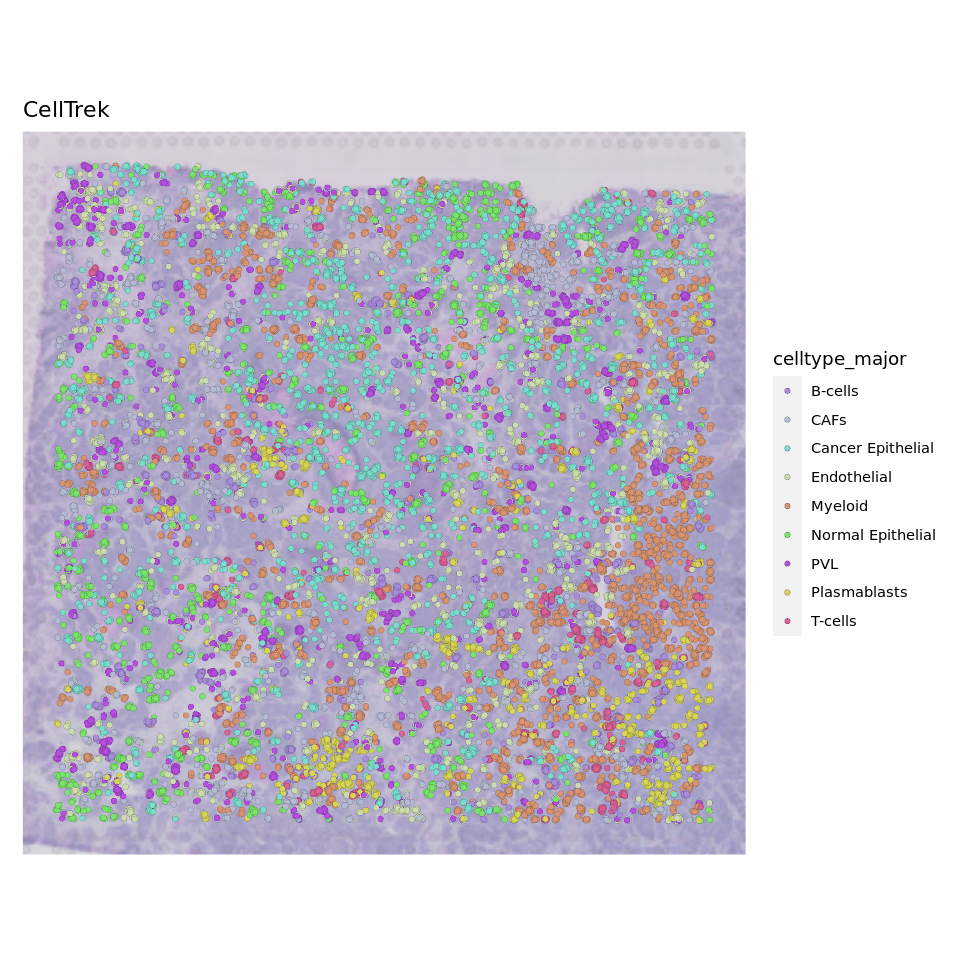

In [51]:
options(repr.plot.width = 8, repr.plot.height = 8)
SpatialPlot(cell.trek, group.by = 'celltype_major', pt.size = 1.6, image.alpha = 0.5, cols = cell.colors, stroke = 0.1) + ggtitle('CellTrek')
ggsave(file.path(out.figs.dir, 'celltrek.entire.UMAP.pdf'), width = 8, height = 6)

In [48]:
length(f.ctypes <- cell.trek$celltype_major %>% unique)

[1] 9

In [49]:
f.ctypes <- cell.trek$celltype_major %>% unique
gps <- lapply(f.ctypes, function(ct) {
    h.cells <- subset(cell.trek, celltype_major == ct) %>% Cells
    obj.sub <- cell.trek[, h.cells]
    SpatialDimPlot(obj.sub, image.alpha = 1, group.by = 'celltype_major', cols = cell.colors[ct], pt.size.factor = 1, crop = FALSE, stroke = 0) + ggtitle(ct) + NoLegend()  
})

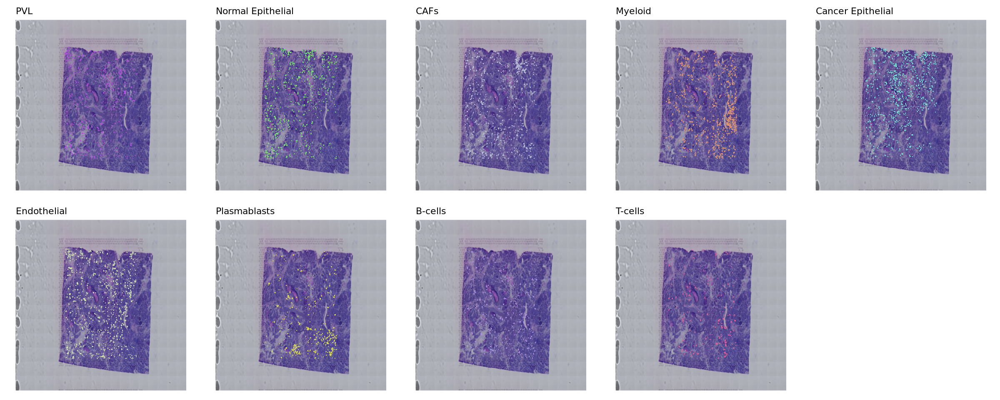

In [52]:
options(repr.plot.width = 20, repr.plot.height = 8)
ggarrange(plotlist = gps, nrow = 2, ncol = 5)
ggsave(file.path(out.figs.dir, 'celltrek.split.UMAP.pdf'), width = 20, height = 8)
ggsave(file.path(out.figs.dir, 'celltrek.split.UMAP.eps'), width = 20, height = 8)

### Showing the projection performance for Seurat

In [166]:
seurat.res <- readRDS('../2.results/BRCA/data/BRCA.1.seurat.RDS') 

In [54]:
seurat.res@meta.data %>% head

,orig.ident,nCount_Spatial,nFeature_Spatial,X,nCount_RNA,nFeature_RNA,patientid,subtype,Classification,nCount_SCT,⋯,prediction.score.Endothelial,prediction.score.CAFs,prediction.score.PVL,prediction.score.B.cells,prediction.score.T.cells,prediction.score.Myeloid,prediction.score.Normal.Epithelial,prediction.score.Plasmablasts,prediction.score.Cancer.Epithelial,prediction.score.max
,<fct>,<dbl>,<int>,<chr>,<int>,<int>,<chr>,<chr>,<chr>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
TACCGATCCAACACTT-1,BRCA,3896,1963,TACCGATCCAACACTT-1,4073,2071,1142243F,TNBC,Artefact,4614,⋯,0.00000000,0.5250017,0.0000000,0.01655654,0.00000000,0.0000000,0.01922573,0.0000000,0.4392160,0.5250017
GATAAGGGACGATTAG-1,BRCA,4448,2201,GATAAGGGACGATTAG-1,4628,2320,1142243F,TNBC,Artefact,4789,⋯,0.03088244,0.5450021,0.0000000,0.04819437,0.02117805,0.0121694,0.00000000,0.0000000,0.3425737,0.5450021
TGTTGGCTGGCGGAAG-1,BRCA,4907,2370,TGTTGGCTGGCGGAAG-1,5116,2494,1142243F,TNBC,Artefact,5021,⋯,0.02088480,0.4267563,0.0000000,0.04687233,0.00000000,0.0000000,0.05971886,0.0000000,0.4457677,0.4457677
GCGAGGGACTGCTAGA-1,BRCA,7818,3276,GCGAGGGACTGCTAGA-1,8170,3464,1142243F,TNBC,Artefact,6120,⋯,0.01306237,0.3643962,0.0000000,0.04365533,0.00000000,0.0000000,0.13031847,0.0000000,0.4485676,0.4485676
GCGCGTTTAAATCGTA-1,BRCA,7178,3136,GCGCGTTTAAATCGTA-1,7534,3345,1142243F,TNBC,Artefact,6033,⋯,0.03293174,0.3684259,0.1005566,0.01058156,0.15253555,0.0000000,0.00991318,0.1692026,0.1558529,0.3684259
GACGACTTTCCAAGAA-1,BRCA,11172,4182,GACGACTTTCCAAGAA-1,11743,4467,1142243F,TNBC,Artefact,6246,⋯,0.00000000,0.0000000,0.0000000,0.00000000,0.00000000,0.0000000,0.67576185,0.0000000,0.3242381,0.6757619


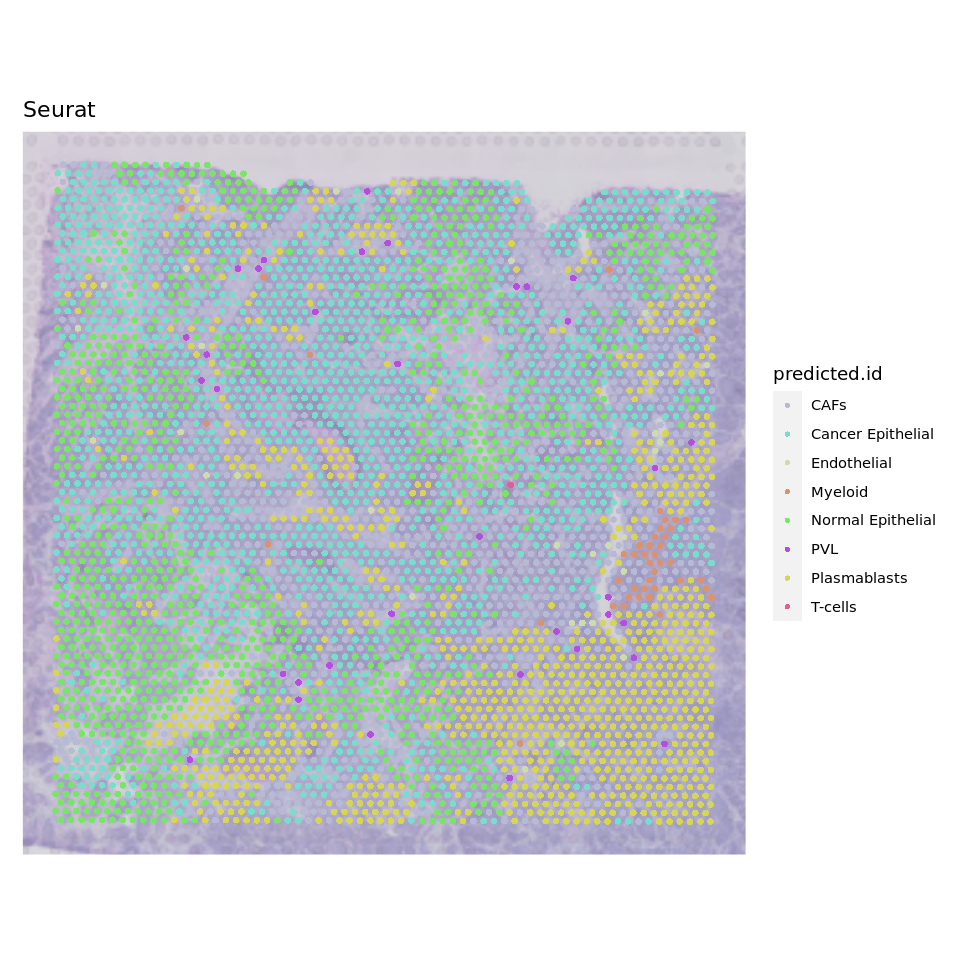

In [59]:
options(repr.plot.width = 8, repr.plot.height = 8)
SpatialPlot(seurat.res, group.by = 'predicted.id', pt.size = 1.8, image.alpha = 0.5, cols = cell.colors, stroke = 0) + ggtitle('Seurat')
ggsave(file.path(out.figs.dir, 'seurat.entire.UMAP.pdf'), width = 8, height = 6)

In [60]:
length(f.ctypes <- seurat.res$predicted.id %>% unique)

[1] 8

In [61]:
f.ctypes <- seurat.res$predicted.id %>% unique
gps <- lapply(f.ctypes, function(ct) {
    h.cells <- subset(seurat.res, predicted.id == ct) %>% Cells
    obj.sub <- seurat.res[, h.cells]
    SpatialDimPlot(obj.sub, image.alpha = 1, group.by = 'predicted.id', cols = cell.colors[ct], pt.size.factor = 1, crop = FALSE, stroke = 0) + ggtitle(ct) + NoLegend()  
})

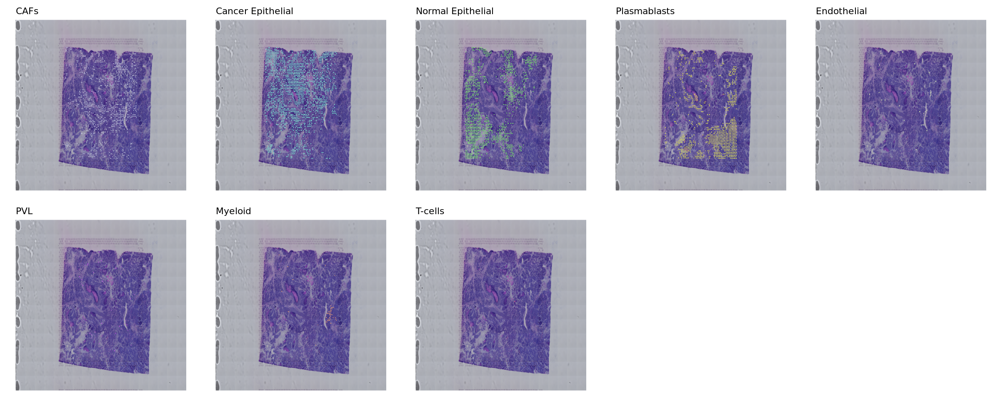

In [62]:
options(repr.plot.width = 20, repr.plot.height = 8)
ggarrange(plotlist = gps, nrow = 2, ncol = 5)
ggsave(file.path(out.figs.dir, 'seurat.split.UMAP.pdf'), width = 20, height = 8)
ggsave(file.path(out.figs.dir, 'seurat.split.UMAP.eps'), width = 20, height = 8)

### Comparison of the performace based on cellular compositions, take CARD deconvolution results as standard

In [177]:
brain.sc$CellTypeNew <- factor(brain.sc$celltype_major, levels = unique(brain.sc$celltype_major))

In [178]:
card.res <- readRDS('../2.results/BRCA/data/BRCA.1.card.RDS')$decon

In [296]:
prop.card <- card.res@Proportion_CARD * 10
prop.card[prop.card <1] <- 0
prop.card <- apply(prop.card, 1, ceiling) %>% t

In [297]:
prop <- rep(0, length(levels(brain.sc$CellTypeNew))) %>% `names<-`(levels(brain.sc$CellTypeNew))
prop.card <- colSums(prop.card) / sum(prop.card) * 100
prop.card <- prop.card[names(prop)]

In [302]:
prop <- rep(0, length(levels(brain.sc$CellTypeNew))) %>% `names<-`(levels(brain.sc$CellTypeNew))
prop.cell2spatial <- cell2spatial$celltype_major %>% table %>% {./sum(.)} * 100
prop[names(prop.cell2spatial)] <- prop.cell2spatial
prop.cell2spatial <- prop

prop <- rep(0, length(levels(brain.sc$CellTypeNew))) %>% `names<-`(levels(brain.sc$CellTypeNew))
prop.cytospace <- cytospace$CellType %>% table %>% {./sum(.)} * 100
prop[names(prop.cytospace)] <- prop.cytospace
prop.cytospace <- prop

prop <- rep(0, length(levels(brain.sc$CellTypeNew))) %>% `names<-`(levels(brain.sc$CellTypeNew))
prop.cell.trek <- cell.trek$celltype_major %>% table %>% {./sum(.)} * 100
prop[names(prop.cell.trek)] <- prop.cell.trek
prop.cell.trek <- prop

prop <- rep(0, length(levels(brain.sc$CellTypeNew))) %>% `names<-`(levels(brain.sc$CellTypeNew))
prop.tangram <- tangram$celltype_major %>% table %>% {./sum(.)} * 100
prop[intersect(names(prop.tangram), names(prop))] <- prop.tangram[intersect(names(prop.tangram), names(prop))]
prop.tangram <- prop

prop <- rep(0, length(levels(brain.sc$CellTypeNew))) %>% `names<-`(levels(brain.sc$CellTypeNew))
prop.seurat <- seurat.res$predicted.id %>% table %>% {./sum(.)} * 100
prop[names(prop.seurat)] <- prop.seurat
prop.seurat <- prop

In [303]:
prop.df <- cbind.data.frame(CARD = prop.card, Cell2Spatial = prop.cell2spatial, CytoSPACE = prop.cytospace, CellTrek = prop.cell.trek, Tangram = prop.tangram, Seurat = prop.seurat)

In [304]:
openxlsx::write.xlsx(prop.df, file = file.path(out.data.dir, 'methods.corr.vs.card.xlsx'))

In [305]:
prop.df$CellType <- rownames(prop.df)
gps <- lapply(colnames(prop.df)[2 : (ncol(prop.df) - 1)], function(meth) {
    plot.df.sub <- prop.df[, c('CARD', meth, 'CellType')] %>% `colnames<-`(c('CARD', 'Y', 'CellType'))
    ggplot(plot.df.sub, aes(x = CARD, y = Y)) + geom_point(size = 4, aes(color = CellType)) + theme_classic() + 
        geom_smooth(method = lm, se = TRUE) + ylab(meth) + ggpubr::stat_cor() + scale_color_manual(values = cell.colors)
})

In [313]:
prop.df

,CARD,Cell2Spatial,CytoSPACE,CellTrek,Tangram,Seurat,CellType
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
Endothelial,0.4500371,2.1044352,2.287946,13.323016,11.11111,0.64799331,Endothelial
CAFs,21.5056582,11.6230354,4.557292,11.501125,11.11111,17.45401338,CAFs
PVL,0.5680080,0.8803521,0.483631,8.996905,11.11111,0.73160535,PVL
B-cells,0.1507406,1.2791577,4.213170,7.386044,11.11111,0.00000000,B-cells
T-cells,5.5206012,0.5186359,0.000000,4.846652,11.11111,0.02090301,T-cells
Myeloid,7.3404116,23.5442229,1.260231,19.864941,11.11111,0.89882943,Myeloid
Normal Epithelial,1.2190326,19.0698788,13.922991,11.669949,11.11111,24.81187291,Normal Epithelial
Plasmablasts,0.9634290,10.7123187,12.439546,7.153911,11.11111,21.13294314,Plasmablasts
Cancer Epithelial,62.2820815,34.6026028,60.835193,15.257456,11.11111,34.30183946,Cancer Epithelial


`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


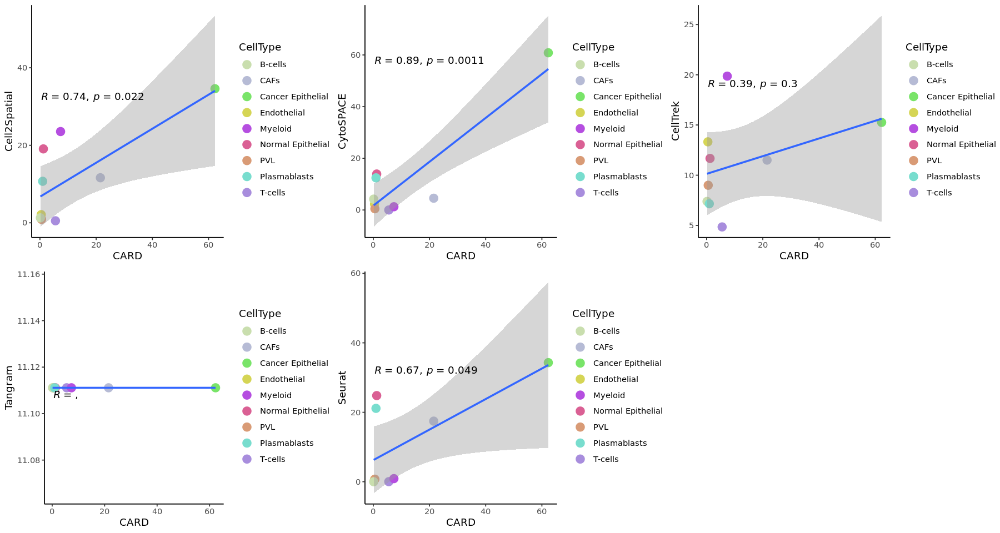

In [306]:
options(repr.plot.width = 15, repr.plot.height = 8)
ggarrange(plotlist = gps, nrow = 2, ncol = 3)
ggsave(file.path(out.figs.dir, 'methods.corr.vs.card.pdf'), width = 15, height = 8)

### J-index analysis

In [30]:
markers.sc <- FindAllMarkers(brain.sc, only.pos = TRUE, logfc.threshold = 0.25, min.pct = 0.25, assay = 'SCT')

Calculating cluster Endothelial

Calculating cluster CAFs

Calculating cluster PVL

Calculating cluster B-cells

Calculating cluster T-cells

Calculating cluster Myeloid

Calculating cluster Normal Epithelial

Calculating cluster Plasmablasts

Calculating cluster Cancer Epithelial



In [32]:
top20.markers.sc <- markers.sc %>% group_by(cluster) %>% top_n(n = 30, wt = avg_log2FC)
marker.lust <- split(top20.markers.sc$gene, top20.markers.sc$cluster)

In [39]:
card.res <- readRDS('../2.results/BRCA/data/BRCA.1.card.RDS')$decon@Proportion_CARD[, names(marker.lust)]
ovp.spots <- intersect(rownames(card.res), colnames(brain.st))
brain.st <- brain.st[, ovp.spots]
card.res <- card.res[ovp.spots, ]
colnames(card.res) <- paste0('Cluster', 1 : ncol(card.res))
brain.st@meta.data <- cbind.data.frame(brain.st@meta.data, card.res)

In [40]:
avgDist <- function(obj, brain.st, ctype, p.cut = 0.05) {
    res <- lapply(1 : length(names(marker.lust)), function(idx) {
        cell.name <- names(marker.lust)[idx]
        scores <- brain.st@meta.data[, paste0('Cluster', idx)] %>% `names<-`(rownames(brain.st@meta.data))
        pvals <- pnorm(scores, mean = mean(scores), sd = sd(scores), lower.tail = FALSE)
        spots <- pvals[pvals < p.cut] %>% names
        if (length(spots) == 0) return(0)
        if (!(cell.name %in% unique(obj@meta.data[, ctype]))) return(0)
        if (sum(spots %in% obj$SpotName) == 0) return(0)
        #xx <- subset(obj, SpotName %in% spots)
        xx <- obj
        if (!(cell.name %in% unique(xx@meta.data[, ctype]))) return(0)
        xx <- table(xx$SpotName, xx@meta.data[, ctype])
        #pre <- colSums(xx > 0)[cell.name]
        pre <- rownames(xx)[which(xx[, cell.name] > 0)]
        length(intersect(spots, pre)) / length(union(spots, pre)) * 100
    }) %>% unlist(.) %>% as.vector #%>% mean
    mean(res) * sum(res > 0) / length(res)
}

In [1]:
p.cut <- 0.01

In [42]:
xx.1 <- avgDist(cell2spatial, brain.st, 'CellType', p.cut = p.cut)
print(xx.1)

[1] 12.45931


In [43]:
cytospace$SpotName <- cytospace$SpotID 
xx.2 <- avgDist(cytospace, brain.st, 'CellType', p.cut = p.cut)
print(xx.2)

[1] 12.08811


In [44]:
cell.trek$SpotName <- cell.trek$Spot 
xx.3 <- avgDist(cell.trek, brain.st, 'celltype_major', p.cut = p.cut)
print(xx.3)

[1] 11.36494


In [45]:
tangram$SpotName <- tangram$SpotID
xx.4 <- avgDist(tangram, brain.st, 'celltype_major', p.cut = p.cut)
print(xx.4)

[1] 6.344705


In [46]:
seurat.res$SpotName <- rownames(seurat.res@meta.data)
xx.5 <- avgDist(seurat.res, brain.st, 'predicted.id', p.cut = p.cut)
print(xx.5)

[1] 5.896678


In [47]:
plot.df <- cbind.data.frame(Index = c(xx.1, xx.2, xx.3, xx.4, xx.5), Method = c('Cell2Spatial', 'CytoSPACE', 'CellTrek', 'Tangram', 'Seurat'), Data = 'DLPFC')

In [48]:
openxlsx::write.xlsx(plot.df, file = file.path(out.data.dir, 'BRCA.1.acc.xlsx'))